# CT4101 Machine Learning 

## Machine Learning Portfolio: Predicting 30-Day Hospital Readmission in Patients with Diabetes Using Machine Learning

## 3. Audit

### Student Name: Faith Greene

### Student ID: 26256593


This notebook conducts an initial audit of the Diabetes-130 US Hospitals for the Years 1999-2008 dataset. This audit investigates the:

* Dataset shape
* Variable types
* Missing values
* Duplicates
* Target distribution

The findings in this audit will inform the decisions implemented at the preprocessing stage.

#### Dataset Shape

In [46]:
# load the data
import pandas as pd
data = pd.read_csv(r"C:\Users\faith\OneDrive\Documents\MDX1_MSc_Health_Data_Science\CT4101_Machine_Learning\Machine_Learning_Portfolio\CT4101-Machine-Learning-Portfolio\data\raw\diabetic_data.csv")

In [47]:
# investigate the dataset shape
print(f"Number of observations: {data.shape[0]:,}")
print(f"Number of variables: {data.shape[1]}")

Number of observations: 101,766
Number of variables: 50


The original dataset contains 101,766 observations and 50 variables.

#### Variable Types

In [48]:
# Preview the dataset
data.head()

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


#### Column Names & Data Types

In [49]:
column_summary = pd.DataFrame({
    "Variable": data.columns,
    "Data Type": data.dtypes.astype(str).values
})
display(column_summary)

,Variable,Data Type
0,encounter_id,int64
1,patient_nbr,int64
2,race,str
3,gender,str
4,age,str
5,weight,str
6,admission_type_id,int64
7,discharge_disposition_id,int64
8,admission_source_id,int64
9,time_in_hospital,int64


encounter_id and patient_nbr should be converted to strings, as these are categorical variables. 

#### Missing Values

In [50]:
data.head()

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


The diabetes dataset contains missing values represented by "?" that are not necessarily recognised by pandas as missing values when first imported.

In [51]:
# look at the number of question marks and missing values
missing = data.isna() | data.eq("?")

missing_summary = pd.DataFrame({
    "Missing Count": missing.sum(),
    "Missing Percentage": (
        missing.mean() * 100
    ).round(2)
})

display(
    missing_summary.sort_values(
        "Missing Percentage",
        ascending=False
    )
)

,Missing Count,Missing Percentage
weight,98569,96.86
max_glu_serum,96420,94.75
A1Cresult,84748,83.28
medical_specialty,49949,49.08
payer_code,40256,39.56
race,2273,2.23
diag_3,1423,1.40
diag_2,358,0.35
diag_1,21,0.02
patient_nbr,0,0.00


Due to the significant number of missing values of the weight, max_glu_serum, A1Cresult and medical_specialty, these could be removed from the dataset. race, diag_3, diag_2 and diag_1 have a small number of missing values, and so they should be imputed.

#### Duplicates

It should be checked whether or not there are any duplicate rows in the table.

In [52]:
print(
    "Exact duplicate rows:",
    data.duplicated().sum()
)

Exact duplicate rows: 0


There are no duplicate rows in the table, but it should also be checked whether each encounter identifier and patient number are unique.

In [53]:
print(
    "Unique encounters:",
    data["encounter_id"].nunique()
)

print(
    "Duplicate encounter IDs:",
    data["encounter_id"].duplicated().sum()
)

patient_counts = data["patient_nbr"].value_counts()

print(
    "Unique patients:",
    data["patient_nbr"].nunique()
)

print(
    "Patients with multiple encounters:",
    (patient_counts > 1).sum()
)

print(
    "Maximum encounters per patient:",
    patient_counts.max()
)

Unique encounters: 101766
Duplicate encounter IDs: 0
Unique patients: 71518
Patients with multiple encounters: 16773
Maximum encounters per patient: 40


Some patients had multiple encounters. These should not be separated when splitting the data into training, validation and test splits. This is to reduce data leakage.

#### Target Distribution

The target variable for this project is "readmitted" which is a categorical variable, but will be converted to a binary variable in this case. A readmission within 30 days is encoded as 1, and a readmission outside of 30 days, or no readmission is encoded as 0.

In [54]:
print(data["readmitted"].value_counts())

# Create binary target variable
binary_target = (
    data["readmitted"] == "<30"
).astype(int)

# Calculate frequencies
target_counts = binary_target.value_counts().sort_index()

# Calculate percentages
target_percentages = (
    binary_target.value_counts(normalize=True)
    .sort_index() * 100
)

# Create summary table
target_summary = pd.DataFrame({
    "Count": target_counts,
    "Percentage": target_percentages.round(2)
})

target_summary.index = [
    "Not Readmitted Within 30 Days (0)",
    "Readmitted Within 30 Days (1)"
]

display(target_summary)

readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64


,Count,Percentage
Not Readmitted Within 30 Days (0),90409,88.84
Readmitted Within 30 Days (1),11357,11.16


This data can also be visualised.

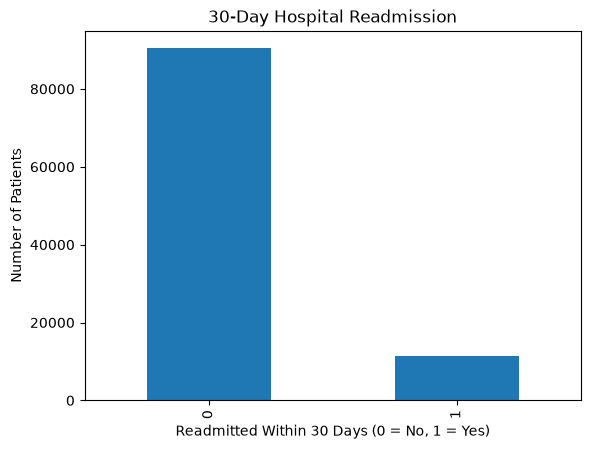

In [55]:
# Create binary target variable
binary_target = (data["readmitted"] == "<30").astype(int)

# Plot
import matplotlib.pyplot as plt
binary_target.value_counts().sort_index().plot(kind="bar")

plt.title("30-Day Hospital Readmission")
plt.xlabel("Readmitted Within 30 Days (0 = No, 1 = Yes)")
plt.ylabel("Number of Patients")
plt.show()

This distribution indicates that there is a class imbalance, with significantly fewer readmissions within 30 days. Therefore, if accuracy is used alone as an evaluation metric, this may give a misleading indication of performance. 